# Task 2 - Exploratory Data Analysis (EDA)
**Name:** Rabia | **Track:** Data Analytics, Veda Technology | **Dataset:** Iris
**Tools:** Python, Pandas, Matplotlib, Seaborn

In this notebook I explore the Iris dataset to understand its patterns, relationships and outliers before drawing any conclusions. Each chart answers one question and has a short observation under it.

## 1. Importing libraries and loading the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

sns.set_style("whitegrid")

# load iris from sklearn and make it a normal dataframe
iris = load_iris(as_frame=True)
df = iris.frame
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df = df.drop(columns="target")
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. First look at the data

In [2]:
print("Shape:", df.shape)
print()
df.info()

Shape: (150, 5)

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 1


**Observation:** The dataset has 150 rows and 5 columns (4 numeric measurements in cm and 1 species column). There are no missing values. There is 1 duplicate row, but I am keeping it because two different flowers can have the same measurements, and removing it would make the species unequal.

## 3. Summary statistics

In [4]:
df.describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [5]:
df.groupby('species').mean().round(2)

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


**Observation:** Petal length has the biggest spread (std 1.77) compared to sepal width (std 0.44). The mean petal length is very different for each species: setosa 1.46 cm, versicolor 4.26 cm and virginica 5.55 cm. Petal measurements seem more useful than sepal measurements for telling species apart.

## 4. Visualizations

### Chart 1: Are the three species equally represented?

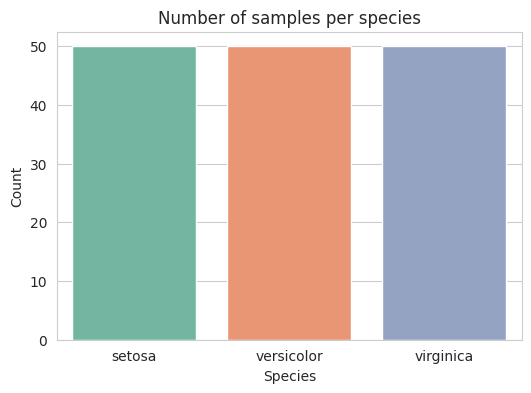

In [6]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="species", palette="Set2")
plt.title("Number of samples per species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

**Observation:** All three species have exactly 50 samples each, so the data is perfectly balanced. This means no species will dominate the averages or any model built later.

### Chart 2: How are the measurements distributed?

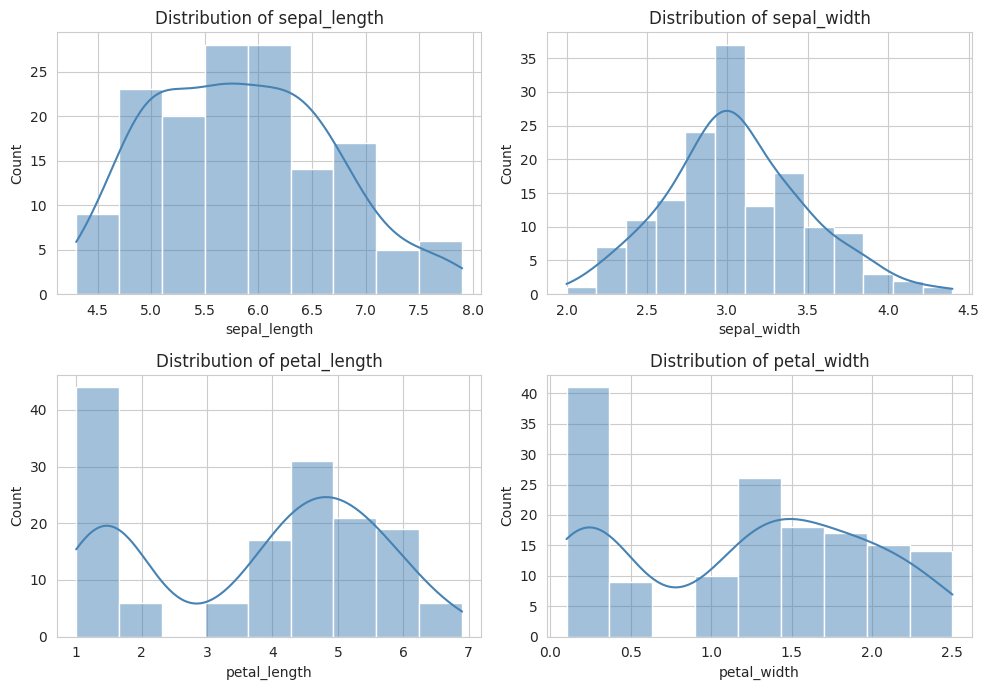

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
for ax, col in zip(axes.flatten(), cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title("Distribution of " + col)
plt.tight_layout()
plt.show()

**Observation:** Sepal length and sepal width look roughly bell shaped. Petal length and petal width are different, they have two separate groups with a gap in the middle (no petals between about 1.9 cm and 3.0 cm). This is because setosa has very small petals compared to the other two species.

### Chart 3: Are there any outliers?

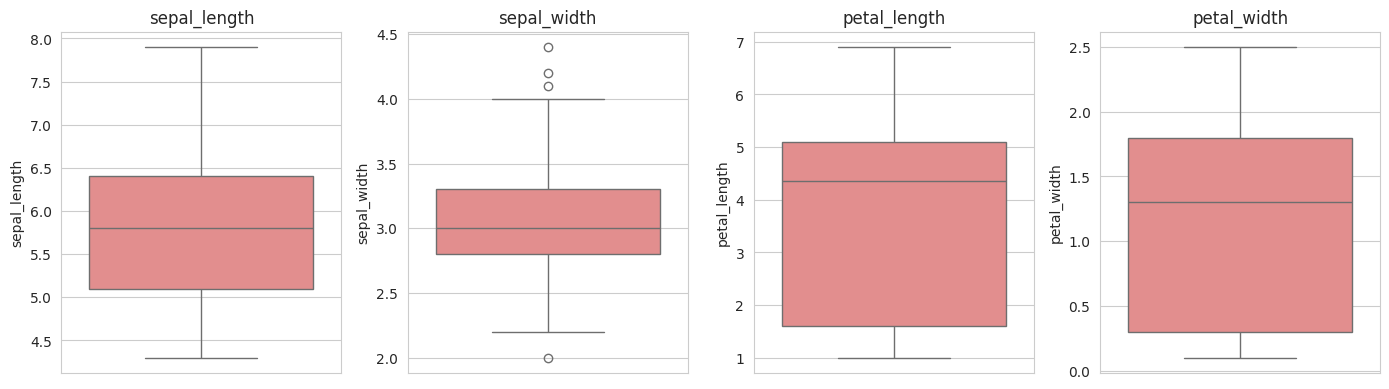

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax, color="lightcoral")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [9]:
# checking the outliers with the IQR rule to be sure
for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    out = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(col, "->", len(out), "outliers")

sepal_length -> 0 outliers
sepal_width -> 4 outliers
petal_length -> 0 outliers
petal_width -> 0 outliers


**Observation:** Only sepal width has outliers (4 points). The other three measurements have none. These look like real flowers (3 setosa and 1 versicolor with unusual sepal width) and not data entry mistakes, because the values are still in a believable range, so I am keeping them.

### Chart 4: Which measurements are related to each other?

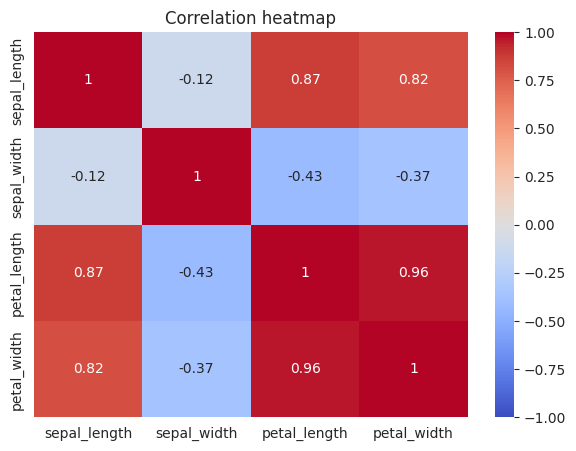

In [10]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.show()

**Observation:** Petal length and petal width are very strongly correlated (0.96). Sepal length is also strongly correlated with petal length (0.87) and petal width (0.82). Sepal width is the odd one out, it has a weak negative correlation with the others (-0.12 to -0.43). Correlation only shows that features move together, it does not mean one causes the other.

### Chart 5: Can petal size separate the species?

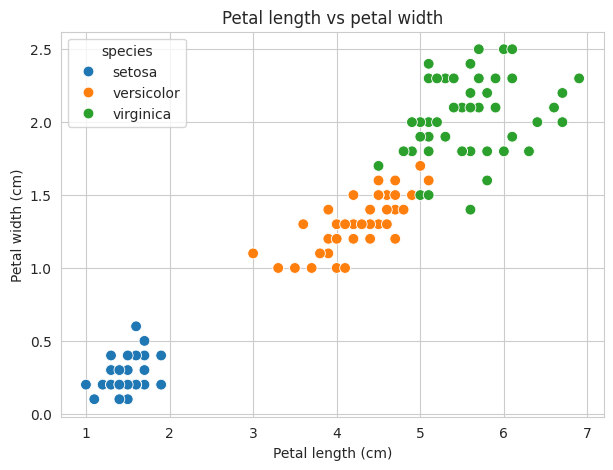

In [11]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="petal_length", y="petal_width", hue="species", s=60)
plt.title("Petal length vs petal width")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.show()

**Observation:** Yes, mostly. Setosa forms its own cluster at the bottom left and is completely separated from the other two. Versicolor and virginica form two groups that touch each other a little in the middle, so a few flowers could be confused. Overall, bigger petals mean species is more likely virginica.

### Chart 6: How does petal length change by species?

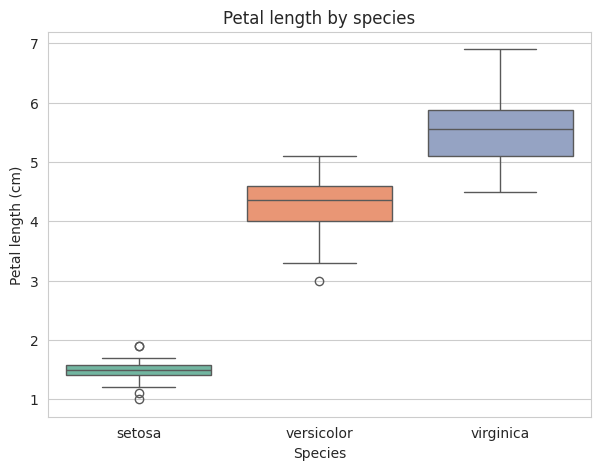

In [12]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="species", y="petal_length", palette="Set2")
plt.title("Petal length by species")
plt.xlabel("Species")
plt.ylabel("Petal length (cm)")
plt.show()

In [13]:
df.groupby('species')['petal_length'].agg(['min', 'max']).round(2)

,min,max
species,,
setosa,1.0,1.9
versicolor,3.0,5.1
virginica,4.5,6.9


**Observation:** Setosa petal length goes from 1.0 to 1.9 cm, which never overlaps with the other species. Versicolor goes from 3.0 to 5.1 cm and virginica from 4.5 to 6.9 cm, so these two overlap only between 4.5 and 5.1 cm. Petal length alone can identify setosa perfectly.

*Note: the task hint mentions line charts for trends over time, but the Iris dataset has no date or time column, so I did not use a line chart here.*

## 5. Top 3 insights
1. **Petal measurements are the best way to tell the species apart.** Setosa has petals of 1.0 to 1.9 cm, which is completely separate from the other two species, and the average petal length goes 1.46, 4.26 and 5.55 cm across the species.
2. **Petal length and petal width are almost the same information.** Their correlation is 0.96, so using both would be repetitive in an analysis or a model. Sepal length (0.87 with petal length) is also related.
3. **Sepal width behaves differently from the rest.** It is the only feature with outliers (4 points) and it has a weak negative correlation with the other features, so it is the least useful feature for separating species.

## 6. Conclusion
The dataset is clean (no missing values) and balanced (50 samples per species). Setosa is easy to separate, while versicolor and virginica overlap a little. In the future, I would check this with a simple classification model to see how accurate it can be.

**What I learned:** Always start with summary statistics, and let each chart answer one question. Outliers should be checked before they are removed, and a high correlation does not mean causation.